# Exploratory Data Analysis (EDA)

## Project: Customer Churn Prediction

### Objective
The objective of this analysis is to explore customer
characteristics, identify patterns associated with churn,
and understand relationships between customer features
and the target variable.

### Analysis Scope
- Univariate Analysis
- Bivariate Analysis
- Missing Value Analysis
- Outlier Detection
- Correlation Analysis
- Churn Behavior Analysis

In [6]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10,6)

#load daaset
file_path=Path.cwd().parent / "data" / "raw" / "Telco_customer_churn.xlsx"

df = pd.read_excel(
    file_path,
    sheet_name = "Telco_Churn"
)

print("Dataset loaded succesfully")
print("Shape:", df.shape)

Dataset loaded succesfully
Shape: (7043, 33)


Feature Classfication

In [8]:
#Numerical features
numerical_features = df.select_dtypes(
    include = ["int64","float64"]
).columns.tolist()


#Categorical features
categorical_features = df.select_dtypes(
    include = ["object"]
).columns.tolist()

print("Numerical Features")
print(numerical_features)

print("\nCategorical Features")
print(categorical_features)



Numerical Features
['Count', 'Zip Code', 'Latitude', 'Longitude', 'Tenure Months', 'Monthly Charges', 'Churn Value', 'Churn Score', 'CLTV']

Categorical Features
['CustomerID', 'Country', 'State', 'City', 'Lat Long', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Total Charges', 'Churn Label', 'Churn Reason']


C:\Users\Adil Abdullayev\AppData\Local\Temp\ipykernel_4512\3886840969.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(


In [9]:
#Missing values
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": df.isnull().mean()*100
})

missing[missing["Missing_Count"]>0].sort_values(
    "Missing_Count",
    ascending = False
)

,Missing_Count,Missing_Percentage
Churn Reason,5174,73.463013


In [10]:
# missing values (Strings)
blank_values = (
    df.select_dtypes(include="object")
    .apply(lambda col: col.astype(str).str.strip().eq("").sum())
)

blank_values[blank_values > 0]

C:\Users\Adil Abdullayev\AppData\Local\Temp\ipykernel_4512\3509475835.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include="object")


Total Charges    11
dtype: int64

Univariate Analysis

Text(0, 0.5, 'Number of Customers')

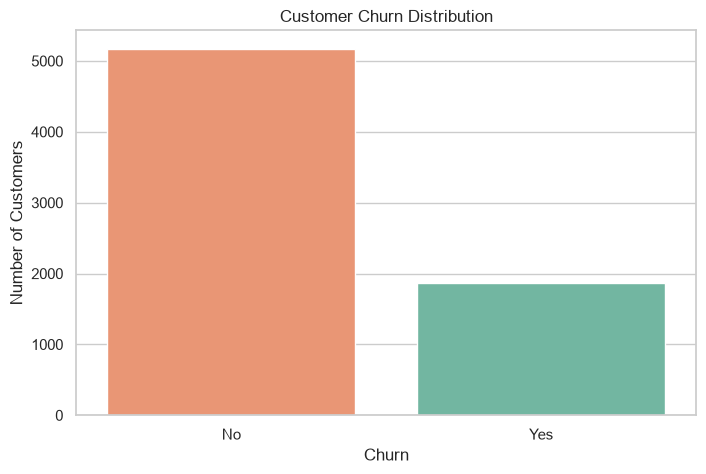

In [11]:
#churn distribution

plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Churn Label",
    hue="Churn Label",
    order=["No","Yes"],
    palette="Set2",
    legend =False
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

In [12]:
churn_rate=df["Churn Label"].value_counts(normalize=True)*100
print(churn_rate)

Churn Label
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


Numerical Distribution

In [13]:
eda_df = df.copy()

eda_df["Total Charges"] = pd.to_numeric(
    eda_df["Total Charges"].astype(str).str.strip(),
    errors = "coerce"
)

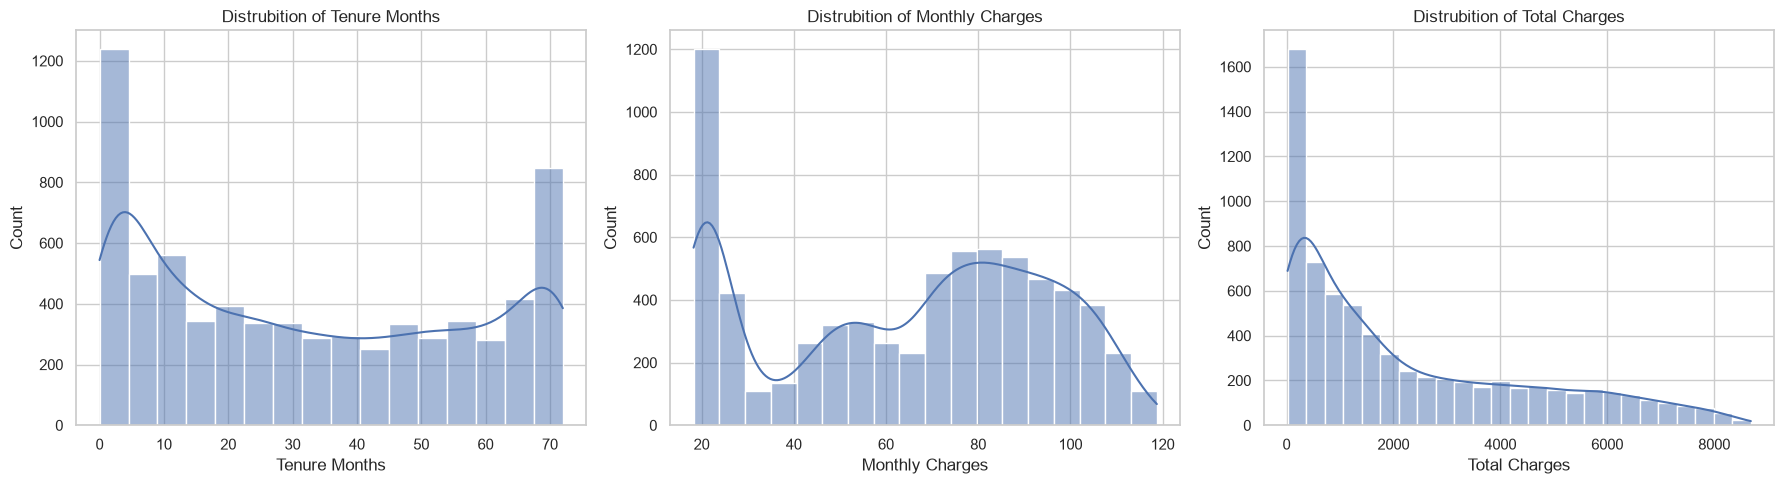

In [17]:
# hystogram and kde graphics
numeric_columns=[
    "Tenure Months",
    "Monthly Charges",
    "Total Charges"
]

fig, axes = plt.subplots(1, 3, figsize = (18,5))

for i, col in enumerate(numeric_columns):
    sns.histplot(
        data = eda_df,
        x = col,
        kde = True,
        ax=axes[i]
    )
    
    axes[i].set_title(f"Distrubition of {col}")

plt.tight_layout()
plt.show()

In [26]:
eda_df[
    [
        "Tenure Months",
        "Monthly Charges",
        "Total Charges"
    ]
].describe()

,Tenure Months,Monthly Charges,Total Charges
count,7043.000000,7043.000000,7032.000000
mean,32.371149,64.761692,2283.300441
std,24.559481,30.090047,2266.771362
min,0.000000,18.250000,18.800000
25%,9.000000,35.500000,401.450000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.850000,3794.737500
max,72.000000,118.750000,8684.800000


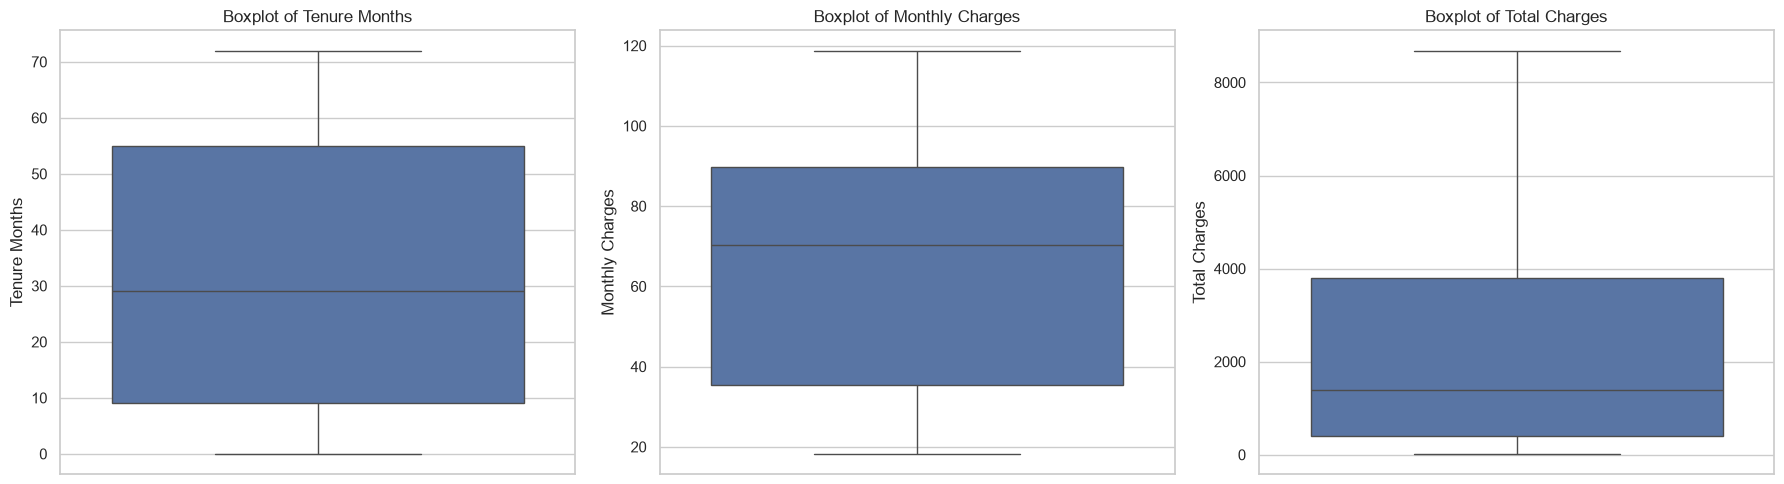

In [20]:
#checking for outliers
fig,axes = plt.subplots(1, 3, figsize = (18,5))

for i, col in enumerate(numeric_columns):
    sns.boxplot(
        data = eda_df,
        y=col,
        ax = axes[i]
    )
    
    axes[i].set_title(f"Boxplot of {col}")
    
plt.tight_layout()
plt.show()

Bivariate analysis: relationships with churn

Text(0, 0.5, 'Customer Count')

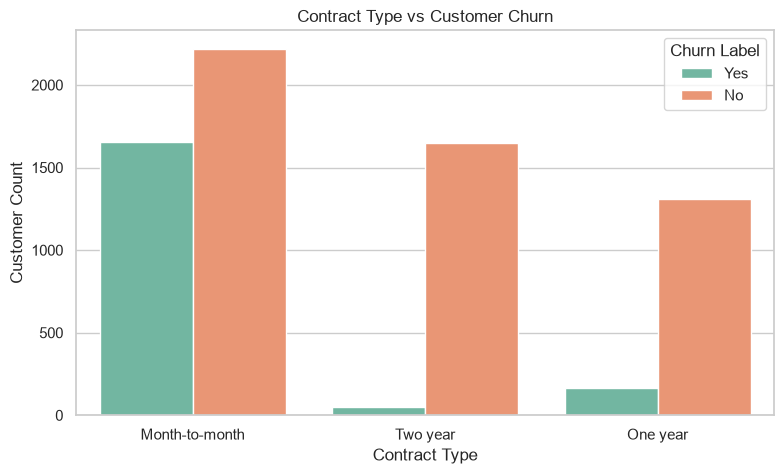

In [22]:
#Contract type vs Churn

plt.figure(figsize=(9,5))

sns.countplot(
    data = df,
    x="Contract",
    hue="Churn Label",
    palette="Set2"
)

plt.title("Contract Type vs Customer Churn")
plt.xlabel("Contract Type")
plt.ylabel("Customer Count")

In [23]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn Label"],
    normalize = "index"
)*100

contract_churn

Churn Label,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


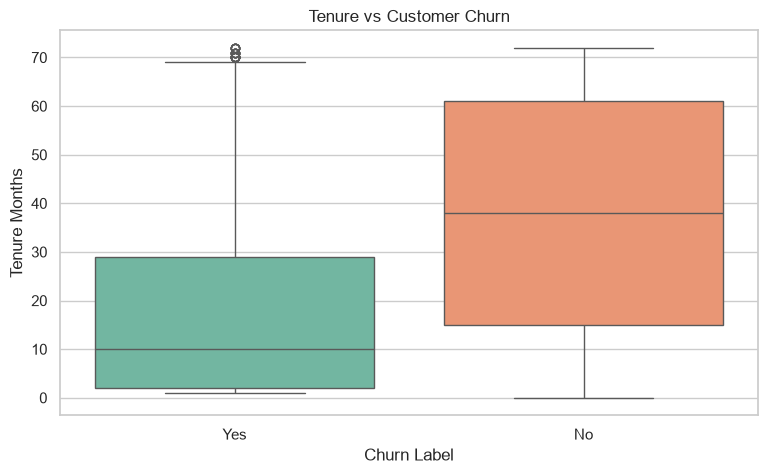

In [24]:
#Tenure vs Churn
plt.figure(figsize=(9,5))

sns.boxplot(
    data = eda_df,
    x="Churn Label",
    y = "Tenure Months",
    hue = "Churn Label",
    palette = "Set2",
    legend = False
)

plt.title("Tenure vs Customer Churn")
plt.show()

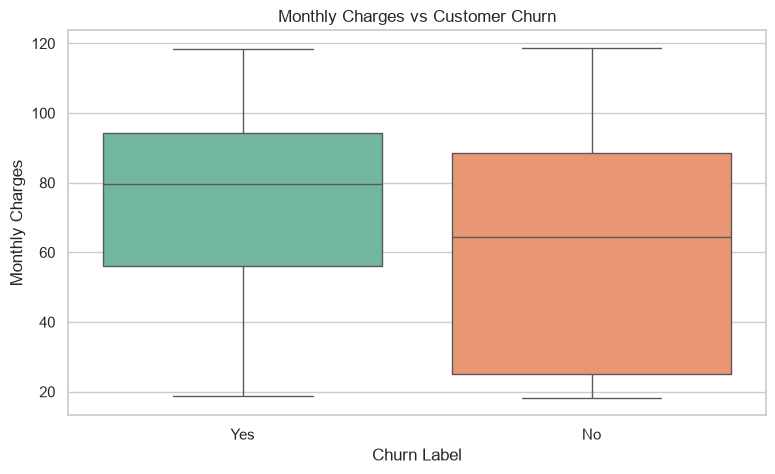

In [25]:
#Monthly charges vs Churn

plt.figure(figsize=(9,5))

sns.boxplot(
    data = eda_df,
    x = "Churn Label",
    y = "Monthly Charges",
    hue ="Churn Label",
    palette = "Set2",
    legend =False
)

plt.title("Monthly Charges vs Customer Churn")
plt.show()

In [28]:
eda_df[
    ["Tenure Months", "Monthly Charges", "Total Charges"]
].describe()

,Tenure Months,Monthly Charges,Total Charges
count,7043.000000,7043.000000,7032.000000
mean,32.371149,64.761692,2283.300441
std,24.559481,30.090047,2266.771362
min,0.000000,18.250000,18.800000
25%,9.000000,35.500000,401.450000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.850000,3794.737500
max,72.000000,118.750000,8684.800000


In [30]:
df["Count"].value_counts()
df["Count"].nunique()

1

In [31]:
column = "Monthly Charges"

Q1 = eda_df[column].quantile(0.25)
Q3 = eda_df[column].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = eda_df[
    (eda_df[column] < lower_bound) |
    (eda_df[column] > upper_bound)
]

print("Q1", Q1)
print("Q3", Q3)
print("IQR", IQR)
print("Lower bound", lower_bound)
print("Upper bound", upper_bound)
print("Outlier count:", len(outliers))

Q1 35.5
Q3 89.85
IQR 54.349999999999994
Lower bound -46.02499999999999
Upper bound 171.375
Outlier count: 0


In [33]:
columns = ["Tenure Months", "Total Charges"]

for column in columns:
    Q1 = eda_df[column].quantile(0.25)
    Q3 = eda_df[column].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = eda_df[
        (eda_df[column] < lower_bound) |
        (eda_df[column] > upper_bound)
    ]
    
    print(f"\n--- {column} ---")
    print("Q1: ",Q1)
    print("Q3: ", Q3)
    print("IQR: ", IQR)
    print("Lower bound:", lower_bound)
    print("Upper bound: ", upper_bound)
    print("Outliers: ", outliers)


--- Tenure Months ---
Q1:  9.0
Q3:  55.0
IQR:  46.0
Lower bound: -60.0
Upper bound:  124.0
Outliers:  Empty DataFrame
Columns: [CustomerID, Count, Country, State, City, Zip Code, Lat Long, Latitude, Longitude, Gender, Senior Citizen, Partner, Dependents, Tenure Months, Phone Service, Multiple Lines, Internet Service, Online Security, Online Backup, Device Protection, Tech Support, Streaming TV, Streaming Movies, Contract, Paperless Billing, Payment Method, Monthly Charges, Total Charges, Churn Label, Churn Value, Churn Score, CLTV, Churn Reason]
Index: []

[0 rows x 33 columns]

--- Total Charges ---
Q1:  401.45
Q3:  3794.7375
IQR:  3393.2875000000004
Lower bound: -4688.481250000001
Upper bound:  8884.66875
Outliers:  Empty DataFrame
Columns: [CustomerID, Count, Country, State, City, Zip Code, Lat Long, Latitude, Longitude, Gender, Senior Citizen, Partner, Dependents, Tenure Months, Phone Service, Multiple Lines, Internet Service, Online Security, Online Backup, Device Protection, Tec

No outliers were detected in the Monthly Charges feature using the 1.5 × IQR rule. All observations fall within the calculated boundaries. Therefore, no records will be removed based on this method at this stage.Next question is what is the categorical variables and churn relation

In [34]:
# calculate the percentage distribution of churn 
# within each contract type
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn Label"],
    normalize = "index"
) * 100

#Display percentages rounded to two decimal places
print(contract_churn.round(2))

Churn Label        No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


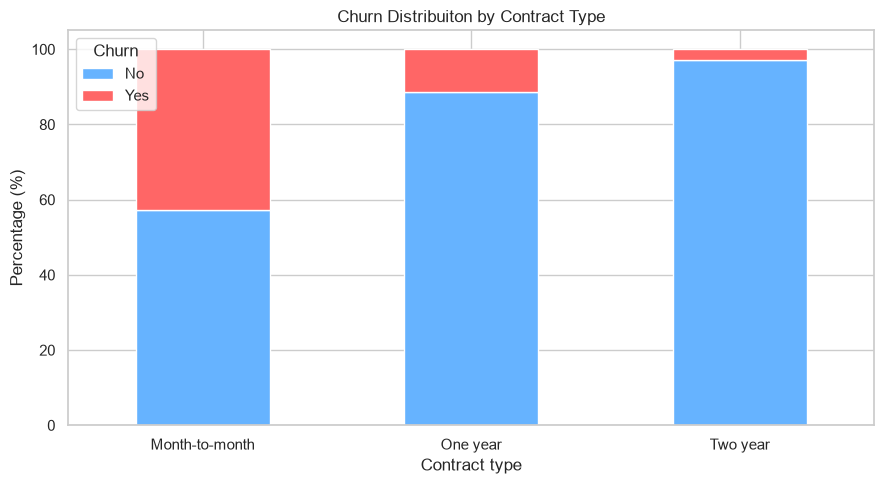

In [36]:
#visualise churn rates by contract type
contract_churn.plot(
    kind = "bar",
    stacked = True,
    figsize = (9,5),
    color = ["#66b3ff", "#ff6666"]
)

plt.title("Churn Distribuiton by Contract Type")
plt.xlabel("Contract type")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title= "Churn")
plt.tight_layout()
plt.show()

### Key Findings

- Month-to-month customers have the highest churn rate at **42.71%**.
- One-year contract customers have a churn rate of **11.27%**.
- Two-year contract customers have the lowest churn rate at **2.83%**.

**Business Insight:**

Customers with month-to-month contracts appear to be substantially more likely to churn than customers with longer-term contracts. This suggests that month-to-month customers may represent an important target segment for customer retention strategies.

**Important Consideration:**

These findings indicate an association, not necessarily causation. Other variables, such as tenure, monthly charges, and customer satisfaction, may also influence this relationship.

In [ ]:
### Churn Analysis by Payment Method

**Business Question:** Is customer churn associated with the payment method?

**Objective:** Compare churn rates across payment methods to identify whether certain payment groups have higher churn rates.

**Methodology:** Calculate the percentage of churned and retained customers within each payment method.

In [39]:
# calculate churn percentages within each payment method

payment_churn = pd.crosstab(
    df["Payment Method"],
    df["Churn Label"],
    normalize = "index"
) * 100

print(payment_churn.round(2))

Churn Label                   No    Yes
Payment Method                         
Bank transfer (automatic)  83.29  16.71
Credit card (automatic)    84.76  15.24
Electronic check           54.71  45.29
Mailed check               80.89  19.11


### Key Findings

- Electronic check users have the highest churn rate at **45.29%**.
- Automatic bank transfer users have a churn rate of **16.71%**.
- Automatic credit card users have the lowest churn rate at **15.24%**.
- Mailed check users have a churn rate of **19.11%**.

**Business Insight:**

Electronic check users represent a potentially high-risk customer segment. The business may benefit from investigating their customer experience and payment preferences.

**Further Investigation:**

We should examine whether electronic check users are also more likely to have month-to-month contracts or shorter customer tenure.

**Important Consideration:**

These results show associations, not causal relationships.

### Churn Analysis by Internet Service

**Business Question:** Is customer churn associated with the type of internet service?

**Objective:** Compare churn rates among customers using different internet service types.

**Methodology:** Calculate the percentage of churned and retained customers within each internet service category.

**Expected Insight:** Identify whether specific internet service groups have higher customer attrition rates.

In [41]:
#Calculate churn percentages within each internet service category

internet_churn = pd.crosstab(
    df["Internet Service"],
    df["Churn Label"],
    normalize = "index"
) * 100

print(internet_churn.round(2))

Churn Label          No    Yes
Internet Service              
DSL               81.04  18.96
Fiber optic       58.11  41.89
No                92.60   7.40


### Key Findings

- Fiber optic customers have the highest churn rate at **41.89%**.
- DSL customers have a churn rate of **18.96%**.
- Customers without internet service have the lowest churn rate at **7.40%**.

**Business Insight:**

Fiber optic customers represent a potentially high-risk customer segment. The business should investigate whether pricing, service quality, contract type, or customer expectations contribute to this higher churn rate.

**Further Investigation:**

Compare internet service type with monthly charges, contract type, and customer tenure to identify possible contributing factors.

**Important Consideration:**

These findings indicate associations and do not establish causal relationships.

### Churn Analysis by Contract Type and Internet Service

**Business Question:** Does the relationship between contract type and churn differ across internet service categories?

**Objective:** Investigate churn rates across combinations of contract type and internet service.

**Methodology:** Use a grouped cross-tabulation to compare churn percentages within each combination of contract type and internet service.

In [42]:
# Calculate churn percentages for each combination
# of contract type and internet service.
contract_internet_churn = pd.crosstab(
    [df["Internet Service"], df["Contract"]],
    df["Churn Label"],
    normalize="index"
) * 100

# Display the results.
print(contract_internet_churn.round(2))

Churn Label                         No    Yes
Internet Service Contract                    
DSL              Month-to-month  67.78  32.22
                 One year        90.70   9.30
                 Two year        98.09   1.91
Fiber optic      Month-to-month  45.39  54.61
                 One year        80.71  19.29
                 Two year        92.77   7.23
No               Month-to-month  81.11  18.89
                 One year        97.53   2.47
                 Two year        99.22   0.78


### Key Findings – Contract Type and Internet Service

The analysis reveals several important patterns:

- Fiber optic customers with month-to-month contracts have the highest churn rate (**54.61%**).
- Churn rates decrease as contract duration increases across all internet service categories.
- Fiber optic customers have higher churn rates than DSL customers within each contract category.
- Customers without internet service and with two-year contracts have the lowest churn rate (**0.78%**).

**Business Insight:**

The combination of fiber optic service and month-to-month contracts represents a potentially high-risk customer segment. Retention strategies could prioritize these customers.

**Analytical Insight:**

The higher churn rate among fiber optic customers remains visible even when comparing customers within the same contract category. Therefore, contract type alone does not fully explain the observed relationship.

**Limitation:**

These are descriptive findings. Further multivariate analysis is required to investigate the independent contribution of each feature.

### Churn Analysis by Customer Tenure

**Business Question:** Are newer customers more likely to churn than long-term customers?

**Objective:** Investigate the relationship between customer tenure and churn rate.

**Methodology:** Divide customer tenure into four groups and calculate the churn percentage within each group.

In [43]:
# define cusomer tenure groups

bins = [0, 12, 24, 48, 72]

labels = [
    "0-12 Months",
    "13-24 Months",
    "25-48 Months",
    "49-72 Months"
]

# create a new categorical tenure feature
tenure_df = df.copy()

tenure_df["Tenure Group"] = pd.cut(
    tenure_df["Tenure Months"],
    bins = bins,
    labels = labels,
    include_lowest = True
)

# calculate churn percentages within each tenure group
tenure_churn = pd.crosstab(
    tenure_df["Tenure Group"],
    tenure_df["Churn Label"],
    normalize = "index"
) * 100

print(tenure_churn.round(2))



Churn Label      No    Yes
Tenure Group              
0-12 Months   52.56  47.44
13-24 Months  71.29  28.71
25-48 Months  79.61  20.39
49-72 Months  90.49   9.51


In [56]:
from pathlib import Path

# 
#
FIGURES_DIR = Path("reports/figures")

if not FIGURES_DIR.exists() and Path("../reports/figures").exists():
    FIGURES_DIR = Path("../reports/figures")

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Figure directory:", FIGURES_DIR.resolve())

Figure directory: E:\format öncesi\ai_projects\churn\customer-churn-prediction\reports\figures


In [57]:
plt.savefig(
    FIGURES_DIR / "churn_rate_by_tenure.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 1000x600 with 0 Axes>

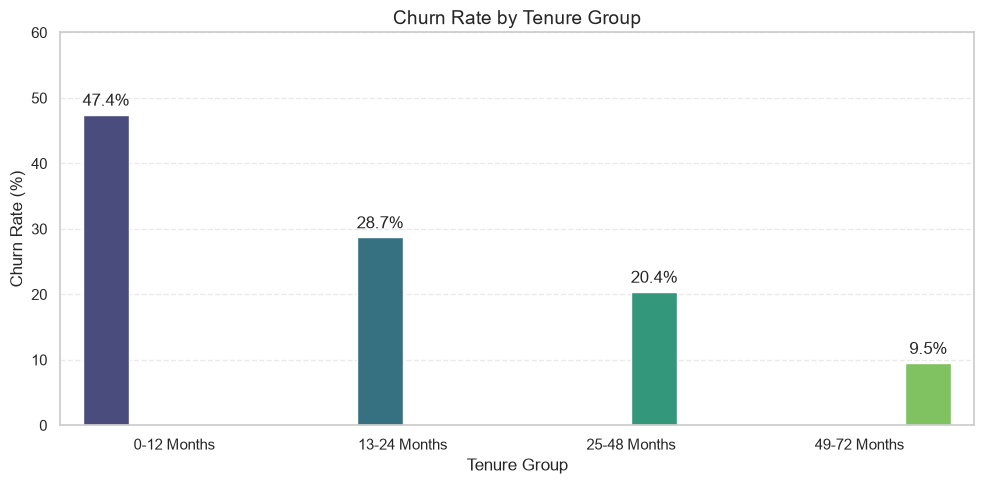

In [48]:
# 
churn_rates = tenure_churn["Yes"]

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=churn_rates.index,
    y=churn_rates.values,
    hue=churn_rates.index,
    palette="viridis",
    legend=False
)

# 
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=4)

plt.title("Churn Rate by Tenure Group", fontsize=14)
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 60)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(
    "../reports/figures/churn_rate_by_tenure.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Key Findings – Churn Analysis by Customer Tenure

The analysis reveals a clear negative relationship between customer tenure and churn rate:

- Customers with 0–12 months of tenure have the highest churn rate (**47.44%**).
- Customers with 13–24 months of tenure have a churn rate of **28.71%**.
- Customers with 25–48 months of tenure have a churn rate of **20.39%**.
- Customers with 49–72 months of tenure have the lowest churn rate (**9.51%**).

**Business Insight:**

New customers appear to be significantly more vulnerable to churn. Customer retention initiatives should prioritize the first year of the customer lifecycle, with particular attention to onboarding and early customer experience.

**Analytical Insight:**

Churn rates consistently decrease across the defined tenure groups. Customer tenure may therefore be an important predictive feature in the churn classification model.

**Limitation:**

These are descriptive findings based on observed customer records. They do not establish causality or directly estimate future churn probabilities.

### Customer Distribution by Tenure Group

**Objective:** Examine the number of customers in each tenure group to provide context for the churn percentages.

**Why is this important?** Churn rates should always be interpreted alongside group sizes. A percentage based on a small group may be less stable than one based on a large group.

In [44]:
# count customers in each tenure group
tenure_counts = tenure_df["Tenure Group"].value_counts(
    sort=False
)

# Display customer counts
print(tenure_counts)

Tenure Group
0-12 Months     2186
13-24 Months    1024
25-48 Months    1594
49-72 Months    2239
Name: count, dtype: int64


In [46]:
#calclate churned and retrained customer counts 
# for each tenure group

tenure_customer_counts = pd.crosstab(
    tenure_df["Tenure Group"],
    tenure_df["Churn Label"]
)

print(tenure_customer_counts)

Churn Label     No   Yes
Tenure Group            
0-12 Months   1149  1037
13-24 Months   730   294
25-48 Months  1269   325
49-72 Months  2026   213


In [ ]:
## Customer Count by Tenure Group and Churn Status

This grouped bar chart compares the number of churned and retained customers in each tenure group.

Unlike percentage-based visualizations, this chart highlights the actual number of customers behind each group.

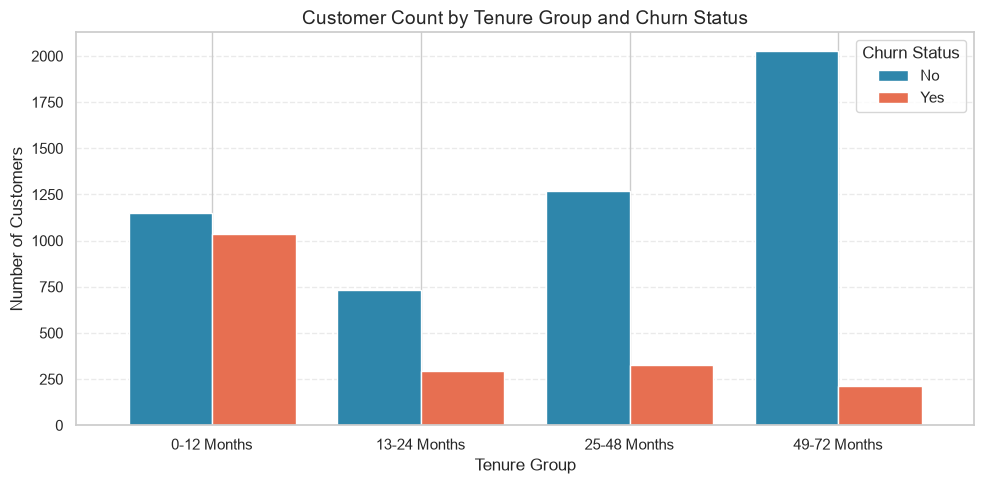

In [49]:
#customer count for each tenure groups
tenure_customer_counts = pd.crosstab(
    tenure_df["Tenure Group"],
    tenure_df["Churn Label"]
)

ax = tenure_customer_counts.plot(
    kind="bar",
    figsize=(10, 5),
    color=["#2E86AB", "#E76F51"],
    width=0.8
)

plt.title("Customer Count by Tenure Group and Churn Status", fontsize=14)
plt.xlabel("Tenure Group")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.legend(title="Churn Status")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

plt.savefig(
    "../reports/figures/customer_count_by_tenure.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Churn Distribution Within Tenure Groups

This 100% stacked bar chart shows the proportion of churned and retained customers within each tenure group.

Each bar represents 100% of the customers in that group, making it easier to compare churn composition across tenure categories.

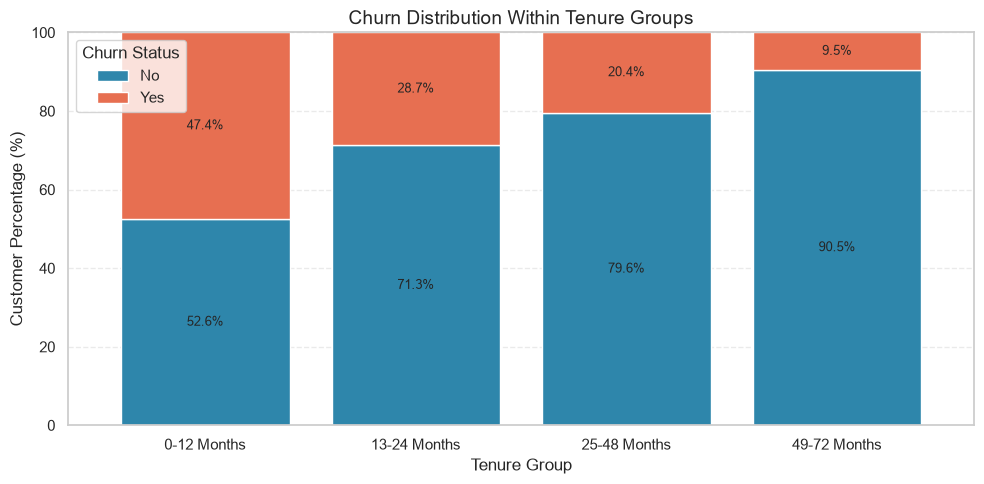

In [51]:
# calculating the percentage distrubition within each group
tenure_percentages = pd.crosstab(
    tenure_df["Tenure Group"],
    tenure_df["Churn Label"],
    normalize="index"
) * 100

ax = tenure_percentages[["No", "Yes"]].plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5),
    color=["#2E86AB", "#E76F51"],
    width=0.8
)

plt.title("Churn Distribution Within Tenure Groups", fontsize=14)
plt.xlabel("Tenure Group")
plt.ylabel("Customer Percentage (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title="Churn Status")

# write for percentages within columns
for container in ax.containers:
    labels = [
        f"{bar.get_height():.1f}%" if bar.get_height() > 5 else ""
        for bar in container
    ]
    ax.bar_label(container, labels=labels, label_type="center", fontsize=9)

plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(
    "../reports/figures/tenure_churn_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Key Findings from Tenure Analysis

- Customers with 0–12 months of tenure have the highest churn rate (47.44%).
- Churn rate decreases as customer tenure increases.
- Only 9.51% of customers in the 49–72 months group churned.
- The first-year customer segment represents an important area for customer retention strategies.

These findings suggest that customer retention efforts may be particularly valuable during the early stages of the customer lifecycle.

Note: These results describe associations in the observed dataset and do not establish causal relationships.

In [ ]:
## 4. Correlation Analysis

In this section, we examine the relationships between numerical variables.

The purpose is to understand how customer tenure, monthly charges, total charges, senior citizen status, and churn are related to each other.

We will first create a correlation table and then visualize the results using a heatmap.

In [ ]:
# picking the variables for corelation analysis

corr_df = eda_df[
    [
        "Tenure Months",
        "Monthly Charges",
        "Total Charges",
        "Churn Values"
    ]
]

## 4. Correlation Analysis

In this section, we examine the relationships between numerical variables.

The purpose is to understand how customer tenure, monthly charges, total charges, senior citizen status, and churn are related to each other.

We will first create a correlation table and then visualize the results using a heatmap.

In [52]:
# 
corr_df = eda_df[
    [
        "Tenure Months",
        "Monthly Charges",
        "Total Charges",
        "Churn Value"
    ]
].copy()

# marking Senior Citizen variable 1/0 instead of Yes/No
corr_df["Senior Citizen"] = (
    df["Senior Citizen"].map({
        "Yes": 1,
        "No": 0
    })
)

# Correlation matrix
correlation_matrix = corr_df.corr(method="pearson")

# table
correlation_matrix.round(3)

,Tenure Months,Monthly Charges,Total Charges,Churn Value,Senior Citizen
Tenure Months,1.000,0.248,0.826,-0.352,0.017
Monthly Charges,0.248,1.000,0.651,0.193,0.220
Total Charges,0.826,0.651,1.000,-0.199,0.102
Churn Value,-0.352,0.193,-0.199,1.000,0.151
Senior Citizen,0.017,0.220,0.102,0.151,1.000


In [ ]:
### Correlation Heatmap

The heatmap visualizes the correlation matrix using colors.

- Red shades represent positive correlations.
- Blue shades represent negative correlations.
- Values close to zero indicate weak linear relationships.

This visualization helps identify relationships between numerical features and the churn target.

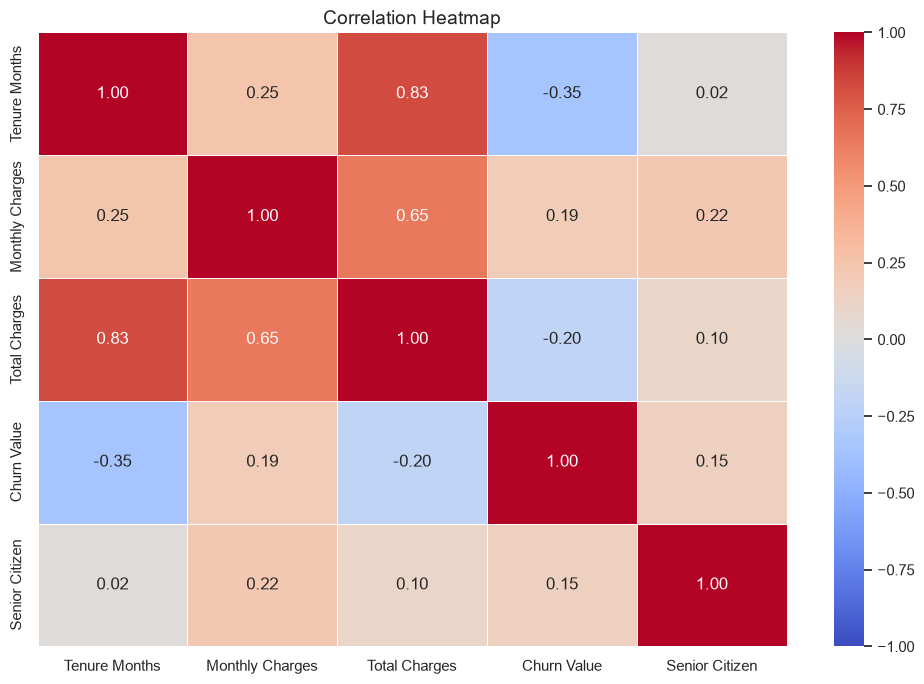

In [58]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,          # prints coeeficients inside cells
    cmap="coolwarm",     # positive and negative relations with different colors
    fmt=".2f",           # 
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Heatmap", fontsize=14)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [54]:
correlation_matrix.style.background_gradient(
    cmap="coolwarm",
    vmin=-1,
    vmax=1
).format("{:.2f}")

,Tenure Months,Monthly Charges,Total Charges,Churn Value,Senior Citizen
Tenure Months,1.00,0.25,0.83,-0.35,0.02
Monthly Charges,0.25,1.00,0.65,0.19,0.22
Total Charges,0.83,0.65,1.00,-0.20,0.10
Churn Value,-0.35,0.19,-0.20,1.00,0.15
Senior Citizen,0.02,0.22,0.10,0.15,1.00


In [ ]:
## 5. Monthly Charges Analysis by Churn

In this section, we compare monthly charges between customers who churned and customers who stayed.

We use descriptive statistics to examine the differences in average and median monthly charges.

A box plot will also help us compare the distributions and identify potential differences between the two groups.

In [59]:
# investigate Monthly Charges variables for Churn Label groups
monthly_charges_summary = df.groupby("Churn Label")["Monthly Charges"].agg(
    Customer_Count="count",
    Mean="mean",
    Median="median",
    Q1=lambda x: x.quantile(0.25),
    Q3=lambda x: x.quantile(0.75)
)

# 
monthly_charges_summary.round(2)

,Customer_Count,Mean,Median,Q1,Q3
Churn Label,,,,,
No,5174,61.27,64.43,25.10,88.4
Yes,1869,74.44,79.65,56.15,94.2


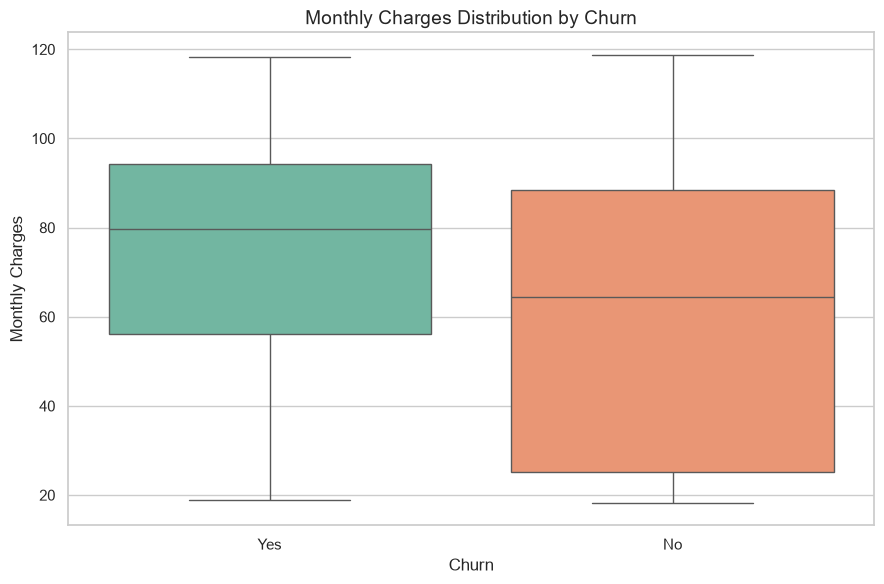

In [60]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="Churn Label",
    y="Monthly Charges",
    hue="Churn Label",
    palette="Set2",
    legend=False
)

plt.title("Monthly Charges Distribution by Churn", fontsize=14)
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "monthly_charges_by_churn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Monthly Charges – Key Findings

Customers who churned had higher monthly charges than customers who stayed.

- The average monthly charge was 74.44 for churned customers and 61.27 for non-churned customers.
- The median monthly charge was also higher among churned customers (79.65 vs. 64.43).
- The difference suggests that monthly charges may be associated with customer churn.

However, this descriptive analysis does not establish a causal relationship between monthly charges and churn.

## 6. Tenure Months Analysis by Churn

In this section, we compare customer tenure between churned and non-churned customers.

The goal is to understand whether customers who leave the company tend to have shorter relationships with the company.

We will use descriptive statistics and visualizations to compare the two groups.

In [61]:
# group costumers by Churn Label value
tenure_summary = df.groupby("Churn Label")["Tenure Months"].agg(
    Customer_Count="count",
    Mean="mean",
    Median="median",
    Q1=lambda x: x.quantile(0.25),
    Q3=lambda x: x.quantile(0.75)
)


tenure_summary.round(2)

,Customer_Count,Mean,Median,Q1,Q3
Churn Label,,,,,
No,5174,37.57,38.0,15.0,61.0
Yes,1869,17.98,10.0,2.0,29.0


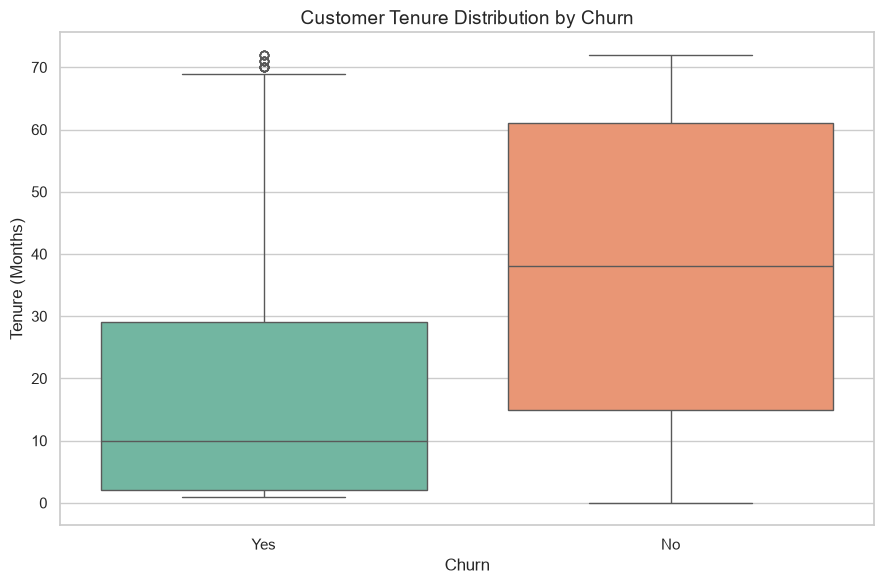

In [62]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="Churn Label",
    y="Tenure Months",
    hue="Churn Label",
    palette="Set2",
    legend=False
)

plt.title("Customer Tenure Distribution by Churn", fontsize=14)
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "tenure_by_churn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Tenure Months – Key Findings

Customers who churned had considerably shorter relationships with the company.

- The average tenure was 17.98 months for churned customers, compared to 37.57 months for non-churned customers.
- The median tenure was 10 months for churned customers and 38 months for non-churned customers.
- 25% of churned customers left within the first 2 months.

These findings suggest that customer churn is particularly concentrated among customers with shorter tenure. Early customer retention may therefore be an important area for further analysis.

## 7. Senior Citizen Analysis by Churn

In this section, we investigate the relationship between senior citizen status and customer churn.

We compare the number of customers and churn rates between senior and non-senior customer groups.

In [64]:
# calculate churn rate Senior Citizen groups
senior_churn_summary = df.groupby("Senior Citizen").agg(
    Customer_Count=("Churn Value", "count"),
    Churned_Customers=("Churn Value", "sum"),
    Churn_Rate=("Churn Value", "mean")
)


senior_churn_summary["Churn_Rate"] *= 100


senior_churn_summary.round(2)

,Customer_Count,Churned_Customers,Churn_Rate
Senior Citizen,,,
No,5901,1393,23.61
Yes,1142,476,41.68


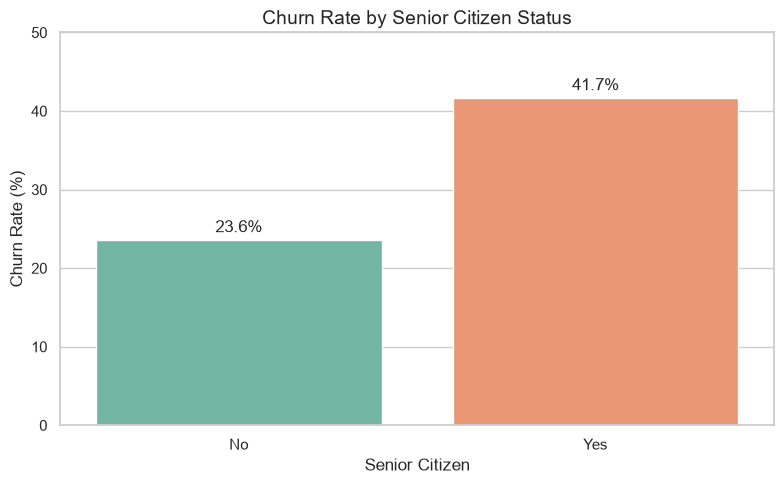

In [65]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=senior_churn_summary.reset_index(),
    x="Senior Citizen",
    y="Churn_Rate",
    hue="Senior Citizen",
    palette="Set2",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.title("Churn Rate by Senior Citizen Status", fontsize=14)
plt.xlabel("Senior Citizen")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "senior_citizen_churn_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Senior Citizen – Key Findings

Senior customers had a higher churn rate than non-senior customers.

- The churn rate among non-senior customers was 23.61%.
- The churn rate among senior customers was 41.68%.
- The difference between the two groups was 18.07 percentage points.

This suggests that senior citizen status may be associated with customer churn. However, this relationship does not imply causation.

## 8. Partner and Dependents Analysis by Churn

In this section, we investigate whether customers' family status is associated with churn.

We compare churn rates between customers who have a partner or dependents and those who do not.

In [66]:
# investigating partner and dependents separetely
family_features = ["Partner", "Dependents"]

for feature in family_features:

    summary = df.groupby(feature)["Churn Value"].agg(
        Customer_Count="count",
        Churned_Customers="sum",
        Churn_Rate="mean"
    )

    summary["Churn_Rate"] *= 100

    print(f"\nChurn Analysis by {feature}")
    display(summary.round(2))


Churn Analysis by Partner


,Customer_Count,Churned_Customers,Churn_Rate
Partner,,,
No,3641,1200,32.96
Yes,3402,669,19.66



Churn Analysis by Dependents


,Customer_Count,Churned_Customers,Churn_Rate
Dependents,,,
No,5416,1763,32.55
Yes,1627,106,6.52



Churn Analysis by Partner


,Customer_Count,Churned_Customers,Churn_Rate
Partner,,,
No,3641,1200,32.96
Yes,3402,669,19.66



Churn Analysis by Dependents


,Customer_Count,Churned_Customers,Churn_Rate
Dependents,,,
No,5416,1763,32.55
Yes,1627,106,6.52


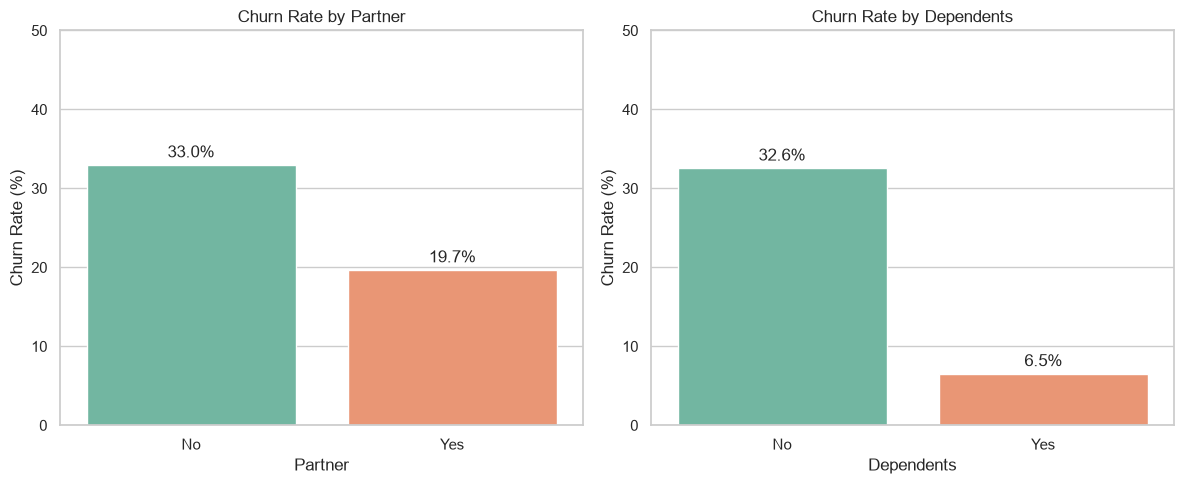

In [67]:

family_features = ["Partner", "Dependents"]


fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, feature in zip(axes, family_features):

    
    summary = df.groupby(feature)["Churn Value"].agg(
        Customer_Count="count",
        Churned_Customers="sum",
        Churn_Rate="mean"
    )

    summary["Churn_Rate"] *= 100

    
    print(f"\nChurn Analysis by {feature}")
    display(summary.round(2))

    
    plot_data = summary.reset_index()

    sns.barplot(
        data=plot_data,
        x=feature,
        y="Churn_Rate",
        hue=feature,
        palette="Set2",
        legend=False,
        ax=ax
    )

    
    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f%%", padding=3)

    ax.set_title(f"Churn Rate by {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Churn Rate (%)")
    ax.set_ylim(0, 50)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "family_features_churn_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Partner and Dependents – Comparative Analysis

In this section, we compare churn rates based on partner and dependent status.

The objective is to identify which family-related characteristic shows a stronger association with customer churn.

,Status,Customer_Count,Churned_Customers,Churn_Rate,Feature
0,No,3641,1200,32.96,Partner
1,Yes,3402,669,19.66,Partner
2,No,5416,1763,32.55,Dependents
3,Yes,1627,106,6.52,Dependents


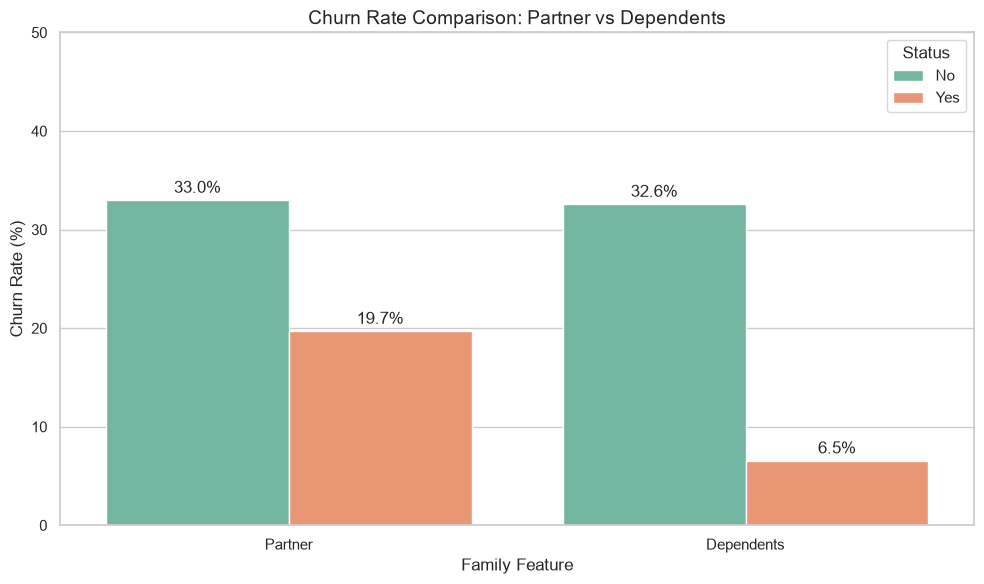

In [68]:
family_features = ["Partner", "Dependents"]

comparison_results = []

for feature in family_features:

    summary = df.groupby(feature)["Churn Value"].agg(
        Customer_Count="count",
        Churned_Customers="sum",
        Churn_Rate="mean"
    ).reset_index()

    summary["Churn_Rate"] *= 100
    summary["Feature"] = feature

    summary = summary.rename(columns={feature: "Status"})

    comparison_results.append(summary)


family_comparison = pd.concat(comparison_results, ignore_index=True)


display(family_comparison.round(2))


plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=family_comparison,
    x="Feature",
    y="Churn_Rate",
    hue="Status",
    palette="Set2"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.title("Churn Rate Comparison: Partner vs Dependents", fontsize=14)
plt.xlabel("Family Feature")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)
plt.legend(title="Status")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "partner_dependents_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Partner and Dependents – Key Findings

Both family-related features show an association with customer churn.

- Customers without a partner had a churn rate of 32.96%, compared to 19.66% for customers with a partner.
- Customers without dependents had a churn rate of 32.55%, compared to 6.52% for customers with dependents.
- Dependents status showed a larger difference in churn rates than partner status.

These findings suggest that family-related characteristics may provide useful information for customer churn prediction. Further model-based analysis will be needed to assess their predictive contribution.

## 9. Contract Type and Tenure Analysis

In this section, we examine the relationship between contract type and customer tenure.

The objective is to compare customer retention duration across different contract types and understand whether long-term contracts are associated with longer customer relationships.

In [69]:
contract_tenure_summary = df.groupby("Contract")["Tenure Months"].agg(
    Customer_Count="count",
    Mean_Tenure="mean",
    Median_Tenure="median",
    Q1=lambda x: x.quantile(0.25),
    Q3=lambda x: x.quantile(0.75)
)


contract_order = ["Month-to-month", "One year", "Two year"]

contract_tenure_summary = contract_tenure_summary.reindex(contract_order)

display(contract_tenure_summary.round(2))

,Customer_Count,Mean_Tenure,Median_Tenure,Q1,Q3
Contract,,,,,
Month-to-month,3875,18.04,12.0,3.0,29.0
One year,1473,42.04,44.0,27.0,58.0
Two year,1695,56.74,64.0,48.0,71.0


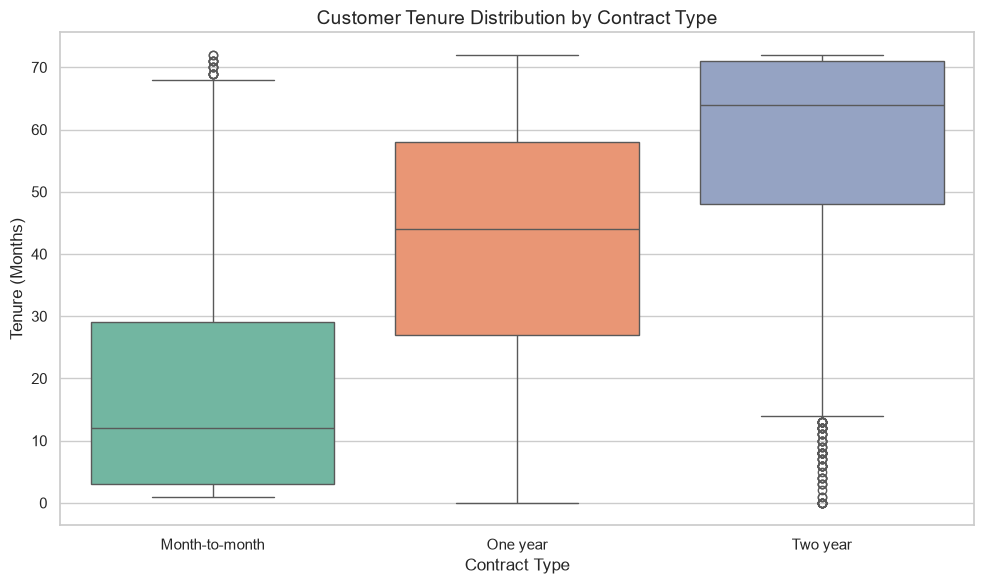

In [70]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Contract",
    y="Tenure Months",
    order=contract_order,
    hue="Contract",
    hue_order=contract_order,
    palette="Set2",
    legend=False
)

plt.title("Customer Tenure Distribution by Contract Type", fontsize=14)
plt.xlabel("Contract Type")
plt.ylabel("Tenure (Months)")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "contract_tenure_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Contract Type and Tenure – Key Findings

Customer tenure varied considerably across contract types.

- Month-to-month customers had a median tenure of 12 months.
- One-year contract customers had a median tenure of 44 months.
- Two-year contract customers had a median tenure of 64 months.
- Customers with longer-term contracts generally had longer customer relationships.

These findings indicate a strong association between contract type and customer tenure. However, the relationship should not be interpreted as causal.## 10. Monthly Charges Analysis by Contract Type

In this section, we compare monthly charges across different contract types.

The objective is to investigate whether monthly charges vary depending on the customer's contract type.

We use descriptive statistics and a box plot to compare the distributions.

,Customer_Count,Mean_Charges,Median_Charges,Q1,Q3
Contract,,,,,
Month-to-month,3875,66.40,73.25,45.85,88.88
One year,1473,65.05,68.75,26.90,94.80
Two year,1695,60.77,64.35,24.02,90.45


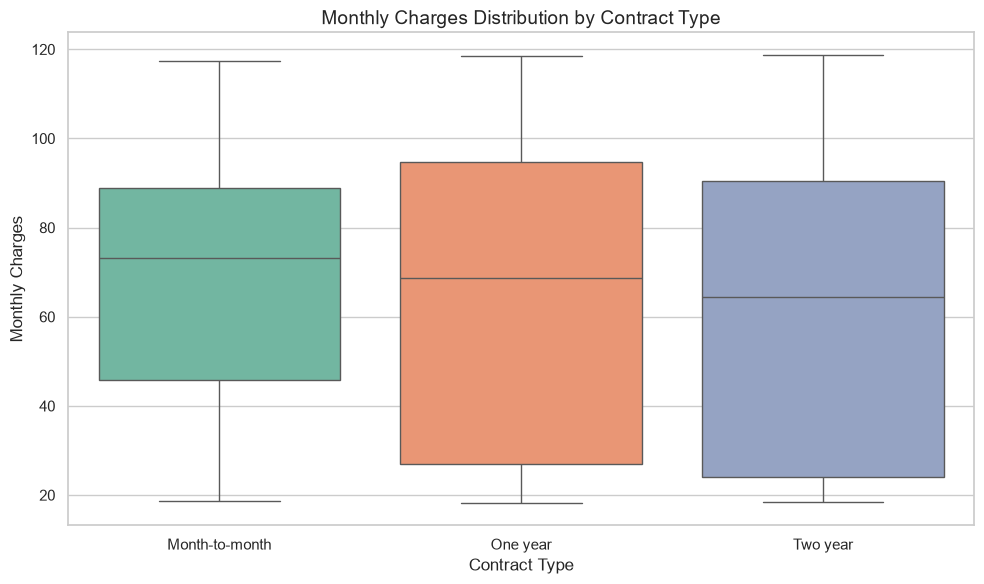

In [71]:

contract_charges_summary = df.groupby("Contract")["Monthly Charges"].agg(
    Customer_Count="count",
    Mean_Charges="mean",
    Median_Charges="median",
    Q1=lambda x: x.quantile(0.25),
    Q3=lambda x: x.quantile(0.75)
)

contract_order = ["Month-to-month", "One year", "Two year"]

contract_charges_summary = contract_charges_summary.reindex(contract_order)


display(contract_charges_summary.round(2))



plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Contract",
    y="Monthly Charges",
    order=contract_order,
    hue="Contract",
    hue_order=contract_order,
    palette="Set2",
    legend=False
)

plt.title("Monthly Charges Distribution by Contract Type", fontsize=14)
plt.xlabel("Contract Type")
plt.ylabel("Monthly Charges")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "monthly_charges_by_contract.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

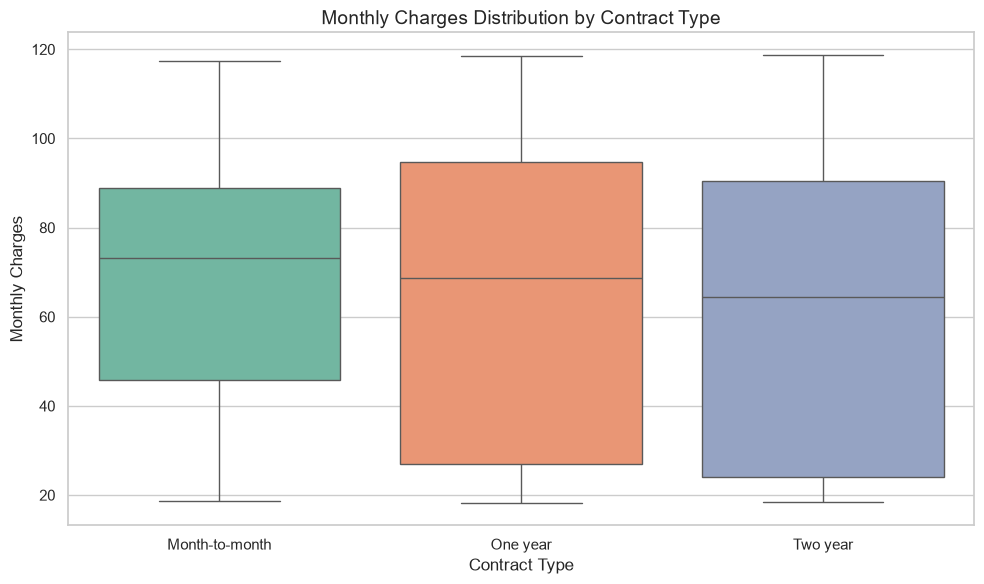

### 11. Monthly Charges by Contract Type and Churn Status

This analysis compares monthly charges across contract types and churn status.

The results show that customers who churned had higher average and median monthly charges across all three contract types.

Key observations:

- Month-to-month customers who churned had a median monthly charge of 79.05, compared to 64.95 for customers who stayed.
- One-year contract customers who churned had a median monthly charge of 95.05, compared to 64.85 for customers who stayed.
- Two-year contract customers who churned had a median monthly charge of 97.28, compared to 63.30 for customers who stayed.

The results suggest an association between higher monthly charges and customer churn.

However, the number of churned customers in one-year and two-year contracts is relatively small. These findings should therefore be interpreted with caution.

These are descriptive findings and do not establish a causal relationship.

In [73]:
monthly_contract_churn = df.groupby(
    ["Contract", "Churn Label"]
)["Monthly Charges"].agg(
    Customer_Count="count",
    Mean_Charges="mean",
    Median_Charges="median"
)

display(monthly_contract_churn.round(2))

Customer_Count  Mean_Charges  Median_Charges
Contract       Churn Label                                              
Month-to-month No                     2220         61.46           64.95
               Yes                    1655         73.02           79.05
One year       No                     1307         62.51           64.85
               Yes                     166         85.05           95.05
Two year       No                     1647         60.01           63.30
               Yes                      48         86.78           97.28

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Contract",
    y="Monthly Charges",
    hue="Churn Label",
    order=["Month-to-month", "One year", "Two year"],
    hue_order=["No", "Yes"],
    palette="Set2"
)

plt.title("Monthly Charges by Contract Type and Churn Status")
plt.xlabel("Contract Type")
plt.ylabel("Monthly Charges")
plt.legend(title="Churn")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "monthly_charges_contract_churn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 12. Exploratory Data Analysis - Summary

In this section, we summarize the main findings from the exploratory data analysis.

The analysis focused on customer demographics, services, contract types, tenure, monthly charges, and churn behavior.

The findings will help guide preprocessing, feature engineering, and model development.